# Hypothesis 1: cumulative frequency constraints (per-user)

Tests section 1 of [`../../frequency_accounting_improvements.md`](../../frequency_accounting_improvements.md).

**Core idea.** The daily per-user cap (`user_frequency_limit.d = C`) is applied **independently**
in each hour, without subtracting impressions already shown to that person in earlier hours.
For the `'d'` cap, the balancer obtains the **correct daily total** (through the full histogram),
but distributes it across hours **in proportion to traffic `w_h`**. Reality is **progressive**:
people consume their cap during the day and then drop out, so delivery is **front-loaded**
relative to traffic.

**What we measure.** Using `(user_id, hour, day)` logs and a daily cap `C`, compute delivery in
two ways and compare the **hourly curves**:

| Curve | Calculation | Meaning |
|---|---|---|
| **true** | budget `u=C`; hours 0→23: `min(requests, remaining)`, subtract from budget | reality (cumulative) |
| **prop** | the same daily total distributed ∝ `w_h` | current model, `'d'` path |
| **flat** | each hour: `min(requests, C/24)` independently | `'h'` path, old conversion |
| **wtd** | each hour: `min(requests, C·w_h)` independently | `'h'` path, fix 0 |

`true` and `prop` have **the same total volume**, so their difference is purely one of **shape**:
the error addressed by hypothesis 1. `flat`/`wtd` show whether fix 0 helps with this issue.

**Assumption.** The ad is shown on every user request until the cap is exhausted (P=1): an
upper bound on the effect. At P<1, the magnitude is smaller and the shape is the same.

In [ ]:
import glob

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rtb_sdk.balancer.seasonal.seasonality import _get_h_type, normalize_counts  # noqa: F401

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

f:\VSProjects\auction_platform\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


## Configuration

`PROFILE_FILE` is one **clean** week. The daily cap resets every day, so we partition by
(user, day). `CAPS` is the set of daily caps `C` to sweep.

In [ ]:
MODE = "hour_of_day"
TIMEZONE = "Europe/Moscow"
PROFILE_FILE = "E:/Logs/report-20260601.parquet"   # clean week

CAPS = [1, 2, 3, 5, 10]        # daily user_frequency_limit.d values to sweep
CAP_MAIN = 5                   # for hourly charts

DUCKDB_THREADS = 4
DUCKDB_MEMORY_LIMIT = "8GB"
DUCKDB_TEMP_DIR = "E:/duckdb_tmp"

# Quick logic check: only the first SAMPLE_DAYS days (None = the entire week).
SAMPLE_DAYS = None

## Loading: (user, day, hour) → cumulative-request window

Materialize `cum` **once**: for each (user, day, hour), store requests and how many requests
occurred **before** that hour on that day. The window is expensive, but subsequent sweeps
over `C` are cheap. Also compute the `w_h` profile and the number of days.

In [ ]:
_local = f"(datetime AT TIME ZONE '{TIMEZONE}')"
USER_EXPR = ("COALESCE(NULLIF(regexp_extract('?' || split_part(path, '?', 2), "
             "'[?&]client_id=([^&]*)', 1), ''), 'EmptyUser')")

con = duckdb.connect()
con.execute(f"PRAGMA threads={DUCKDB_THREADS}")
con.execute(f"PRAGMA memory_limit='{DUCKDB_MEMORY_LIMIT}'")
con.execute(f"PRAGMA temp_directory='{DUCKDB_TEMP_DIR}'")

_file_start = con.execute(
    f"SELECT MIN(datetime)::VARCHAR FROM read_parquet('{PROFILE_FILE}')"
).fetchone()[0]
_where = ""
if SAMPLE_DAYS is not None:
    _where = f"WHERE datetime < TIMESTAMP '{_file_start}' + INTERVAL '{SAMPLE_DAYS} days'"

print(f"Reading {PROFILE_FILE}{' [SAMPLE]' if _where else ' [FULL]'} ...")
con.execute(f"""
    CREATE TEMP TABLE events AS
    SELECT EXTRACT(hour FROM {_local})::INT AS h,
           {USER_EXPR} AS uid,
           date_trunc('day', {_local}) AS day
    FROM read_parquet('{PROFILE_FILE}')
    {_where}
""")

# w_h profile (hourly traffic shares)
_agg = con.execute("SELECT h, COUNT(*) c FROM events GROUP BY h ORDER BY h").fetchdf()
_w = {int(h): float(c) for h, c in zip(_agg["h"], _agg["c"])}
w_arr = np.array([_w.get(h, 0.0) for h in range(24)])
w_arr = w_arr / w_arr.sum()
wdf = pd.DataFrame({"h": range(24), "wh": w_arr})   # for the JOIN in DuckDB

n_days = int(con.execute("SELECT COUNT(DISTINCT day) FROM events").fetchone()[0])
print(f"Days in sample: {n_days}")

# cum: cumulative requests BEFORE each hour within (user, day), computed ONCE.
print("Building cum (user-day window, expensive pass)...")
con.execute("""
    CREATE TEMP TABLE cum AS
    WITH ud AS (
        SELECT uid, day, h, COUNT(*) AS req
        FROM events GROUP BY uid, day, h
    )
    SELECT uid, day, h, req,
        COALESCE(SUM(req) OVER (PARTITION BY uid, day ORDER BY h
                 ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING), 0) AS before
    FROM ud
""")
print("Done. cum materialized.")

Reading E:/Logs/report-20260601.parquet [FULL] ...
Days in sample: 8
Building cum (user-day window, expensive pass)...
Done. cum materialized.


## Simulation: cumulative delivery vs current model

Sweep over `C`; the window is already computed, so aggregation is inexpensive.

In [ ]:
def simulate(C):
    d = con.execute(f"""
        SELECT c.h,
            SUM(GREATEST(0, LEAST(c.req, {C} - c.before))) AS true_d,
            SUM(LEAST(c.req, {C} / 24.0))                  AS flat_d,
            SUM(LEAST(c.req, {C} * w.wh))                  AS wtd_d
        FROM cum c JOIN wdf w ON c.h = w.h
        GROUP BY c.h ORDER BY c.h
    """).fetchdf()
    true = np.zeros(24); flat = np.zeros(24); wtd = np.zeros(24)
    for h, t, f, wv in zip(d["h"].astype(int), d["true_d"], d["flat_d"], d["wtd_d"]):
        true[h], flat[h], wtd[h] = t / n_days, f / n_days, wv / n_days
    T = true.sum()
    prop = T * w_arr                      # current 'd' model: same total, w_h shape
    return {"true": true, "prop": prop, "flat": flat, "wtd": wtd, "T": T}


def tv_shape(a, b):
    """TV between SHAPES (normalize each to a sum of 1)."""
    sa, sb = a.sum(), b.sum()
    if sa == 0 or sb == 0:
        return float("nan")
    return 0.5 * float(np.sum(np.abs(a / sa - b / sb)))


sims = {C: simulate(C) for C in CAPS}
print("Simulation computed for C =", CAPS)

Simulation computed for C = [1, 2, 3, 5, 10]


## Chart 1: hourly delivery (reality vs model), C = CAP_MAIN

The **X axis** is hour of day (0–23); the **Y axis** is average daily impressions in that hour, summed across users. Four curves:

- **`true` (thick black line)**: cumulative reality; each user consumes their daily cap `C` and drops out when exhausted.
- **`prop` (blue, ■)**: current `'d'` model, with the same total volume distributed ∝ `w_h`.
- **`flat` (dashed, ▲)** and **`wtd` (dashed, ✕)**: independent `'h'` paths `min(requests, C/24)` and `min(requests, C·w_h)`; these are contrasts, not the `'d'` model.

`true` and `prop` have the **same daily sum**; their difference is shape only. The title reports `TV(prop,true)` (0.075 at C=5). Daily totals: true=prop=6,674,325; flat=1,015,137; wtd=1,083,416.


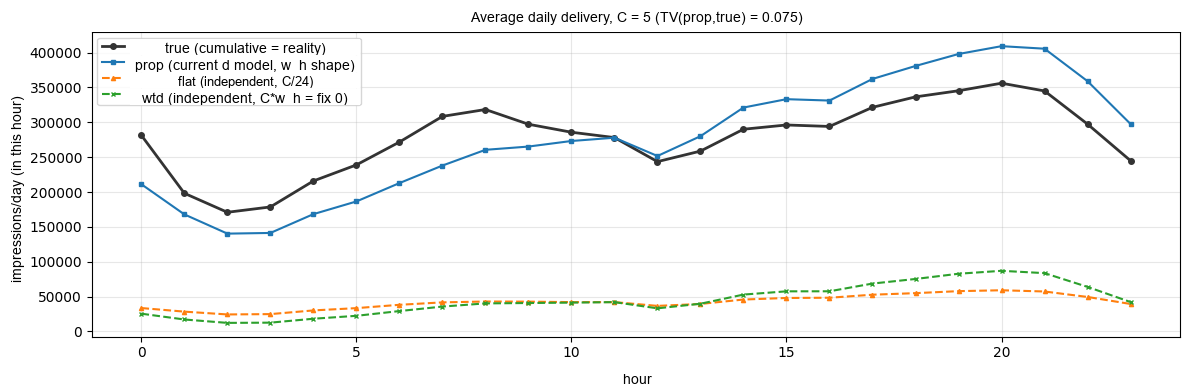

Total volume/day: true=6,674,325  prop=6,674,325 (=true)  flat=1,015,137  wtd=1,083,416


In [ ]:
s = sims[CAP_MAIN]
x = np.arange(24)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(x, s["true"], marker="o", ms=4, lw=2, color="#333", label="true (cumulative = reality)")
ax.plot(x, s["prop"], marker="s", ms=3, label="prop (current 'd' model, w_h shape)")
ax.plot(x, s["flat"], marker="^", ms=3, ls="--", label="flat (independent, C/24)")
ax.plot(x, s["wtd"], marker="x", ms=3, ls="--", label="wtd (independent, C·w_h = fix 0)")
ax.set_title(f"Average daily delivery, C = {CAP_MAIN} "
             f"(TV(prop,true) = {tv_shape(s['prop'], s['true']):.3f})")
ax.set_xlabel("hour"); ax.set_ylabel("impressions/day (in this hour)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Total volume/day: true={s['true'].sum():,.0f}  prop={s['prop'].sum():,.0f} "
      f"(=true)  flat={s['flat'].sum():,.0f}  wtd={s['wtd'].sum():,.0f}")

## Chart 2: hourly model error (prop − true), C = CAP_MAIN

The X axis is hour (0–23). The left panel shows absolute error `prop − true` in impressions/day; its bars sum to zero because daily totals match. The right panel shows relative error `(prop−true)/true`, %.

Red bars are overestimates; blue bars are underestimates. The output reports a **+9.6%** aggregate error over the six highest-volume hours **[8, 17, 18, 19, 20, 21]**. This does not establish a blanket evening bias; use the individual bars for hour-level direction.


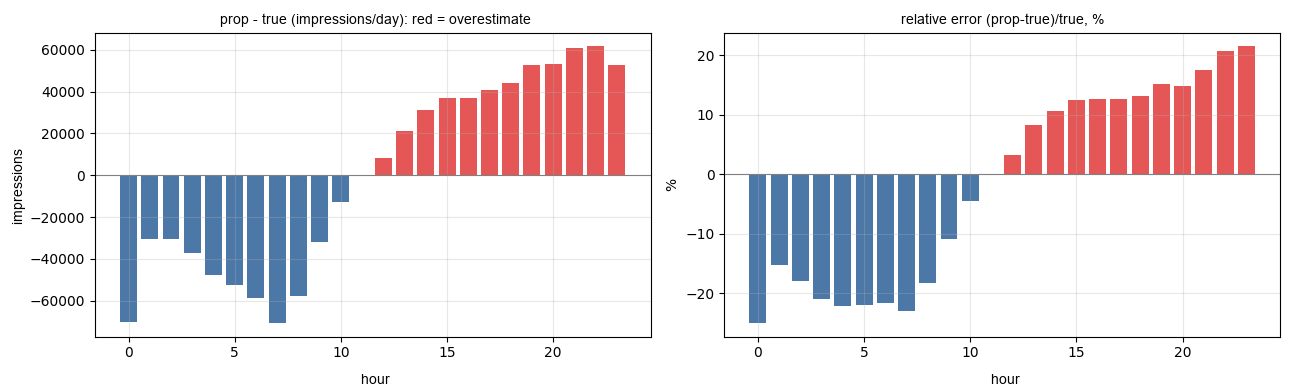

Peak hours (by true): [8, 17, 18, 19, 20, 21]
prop error in peak hours: +9.6%


In [ ]:
s = sims[CAP_MAIN]
err = s["prop"] - s["true"]                     # same total, so Σ err = 0
rel = np.divide(err, s["true"], out=np.zeros_like(err), where=s["true"] > 0) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = ["#E45756" if e > 0 else "#4C78A8" for e in err]
axes[0].bar(x, err, color=colors)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_title("prop − true (impressions/day): red = overestimate")
axes[0].set_xlabel("hour"); axes[0].set_ylabel("impressions")
axes[1].bar(x, rel, color=colors)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_title("relative error (prop−true)/true, %")
axes[1].set_xlabel("hour"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

peak = np.argsort(s["true"])[-6:]               # 6 highest-volume hours
print(f"Peak hours (by true): {sorted(peak.tolist())}")
print(f"prop error in peak hours: {(s['prop'][peak].sum() - s['true'][peak].sum()) / s['true'][peak].sum() * 100:+.1f}%")

## Chart 3: sweep over daily cap C

The left panel compares shape error `TV` vs daily cap `C` (1, 2, 3, 5, 10):
- `TV(prop,true)` is the `'d'` model. Table values are 11.73%, 10.46%, 9.22%, 7.50%, and 5.50%, respectively.
- `TV(flat,true)` and `TV(wtd,true)` are independent `'h'` paths; `wtd` (fix 0) is worse than `flat` here.

The right panel shows independent-model volume / `true`. These `'h'` paths do not reproduce the daily volume of the `'d'` model. Interpret `prop` as the relevant comparison for hypothesis 1.


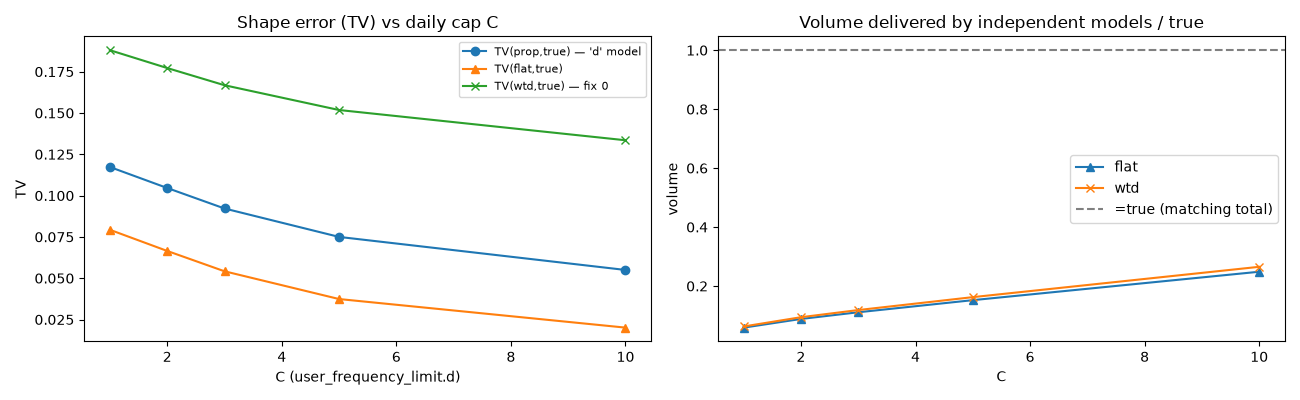

,"TV(prop,true)","TV(flat,true)","TV(wtd,true)",volume flat/true,volume wtd/true
C,,,,,
1,0.1173,0.0793,0.1880,0.0589,0.0628
2,0.1046,0.0665,0.1772,0.0883,0.0942
3,0.0922,0.0542,0.1668,0.1110,0.1185
5,0.0750,0.0374,0.1518,0.1521,0.1623
10,0.0550,0.0201,0.1335,0.2485,0.2652


In [ ]:
rows = []
for C in CAPS:
    s = sims[C]
    rows.append({
        "C": C,
        "TV(prop,true)": tv_shape(s["prop"], s["true"]),
        "TV(flat,true)": tv_shape(s["flat"], s["true"]),
        "TV(wtd,true)": tv_shape(s["wtd"], s["true"]),
        "volume flat/true": s["flat"].sum() / s["T"] if s["T"] else float("nan"),
        "volume wtd/true": s["wtd"].sum() / s["T"] if s["T"] else float("nan"),
    })
swp = pd.DataFrame(rows).set_index("C")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(swp.index, swp["TV(prop,true)"], marker="o", label="TV(prop,true) — 'd' model")
axes[0].plot(swp.index, swp["TV(flat,true)"], marker="^", label="TV(flat,true)")
axes[0].plot(swp.index, swp["TV(wtd,true)"], marker="x", label="TV(wtd,true) — fix 0")
axes[0].set_title("Shape error (TV) vs daily cap C")
axes[0].set_xlabel("C (user_frequency_limit.d)"); axes[0].set_ylabel("TV"); axes[0].legend(fontsize=8)
axes[1].plot(swp.index, swp["volume flat/true"], marker="^", label="flat")
axes[1].plot(swp.index, swp["volume wtd/true"], marker="x", label="wtd")
axes[1].axhline(1.0, color="grey", ls="--", label="=true (correct total)")
axes[1].set_title("Total volume of independent models / true")
axes[1].set_xlabel("C"); axes[1].set_ylabel("ratio"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
swp.round(4).rename(columns={"volume flat/true": "volume flat/true", "volume wtd/true": "volume wtd/true"}).rename(columns={"volume flat/true": "volume flat/true", "volume wtd/true": "volume wtd/true"})

## Effect driver: user distributions

The hypothesis 1 error exists only when users **span multiple hours** and **exceed their cap**
(concentrated users and those below the cap contribute zero). Inspect these distributions:

- **Left:** histogram of the number of hours a user is active per day. Many users spanning
  more than one hour imply substantial potential for cross-hour error.
- **Right:** share of users exceeding daily cap `C` (only they are affected by the cap).
  If this share is nearly zero at realistic `C`, the hypothesis is not relevant.

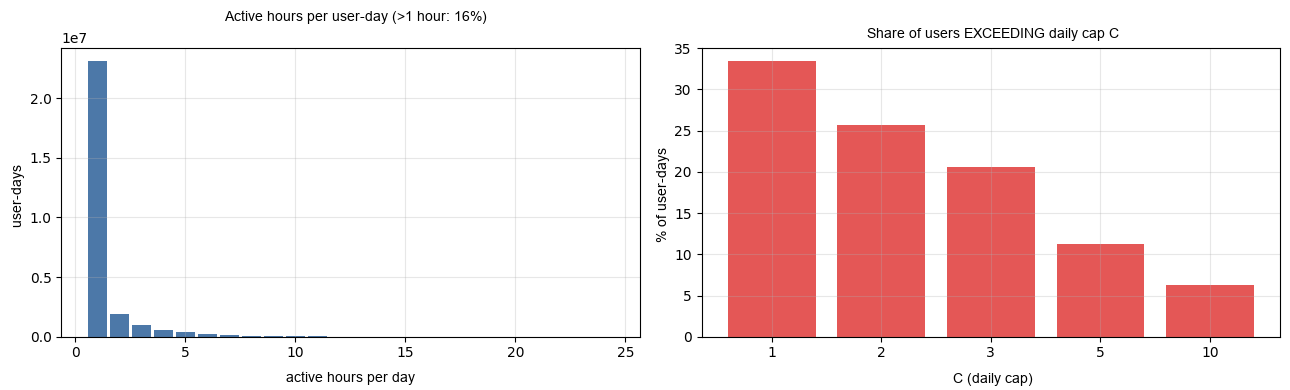

User-days: 27,582,813
Active in >1 hour: 16.3%  (only these create cross-hour error)
  C= 1: exceed cap  33.4%  (if ~0%, the cap does not bind and the hypothesis is irrelevant)
  C= 2: exceed cap  25.7%  (if ~0%, the cap does not bind and the hypothesis is irrelevant)
  C= 3: exceed cap  20.6%  (if ~0%, the cap does not bind and the hypothesis is irrelevant)
  C= 5: exceed cap  11.3%  (if ~0%, the cap does not bind and the hypothesis is irrelevant)
  C=10: exceed cap   6.3%  (if ~0%, the cap does not bind and the hypothesis is irrelevant)


In [ ]:
# === Effect driver: user distributions ======================================
# Exclude EmptyUser: a synthetic pooled uid for anonymous traffic, not a real user.
con.execute("""
    CREATE OR REPLACE TEMP TABLE ustats AS
    SELECT uid, day, SUM(req) AS total_req, COUNT(*) AS active_hours
    FROM cum WHERE uid <> 'EmptyUser'
    GROUP BY uid, day
""")

_hist = con.execute(
    "SELECT active_hours, COUNT(*) AS n FROM ustats GROUP BY active_hours ORDER BY active_hours"
).fetchdf()
n_ud = int(con.execute("SELECT COUNT(*) FROM ustats").fetchone()[0])
frac_multi = float(con.execute(
    "SELECT AVG(CASE WHEN active_hours > 1 THEN 1.0 ELSE 0 END) FROM ustats").fetchone()[0])
frac_exceed = {C: float(con.execute(
    f"SELECT AVG(CASE WHEN total_req > {C} THEN 1.0 ELSE 0 END) FROM ustats").fetchone()[0])
    for C in CAPS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(_hist["active_hours"], _hist["n"], color="#4C78A8", width=0.9)
axes[0].set_title(f"Active hours per user-day (>1 hour: {frac_multi*100:.0f}%)")
axes[0].set_xlabel("active hours per day"); axes[0].set_ylabel("user-days")
axes[1].bar([str(c) for c in CAPS], [frac_exceed[c] * 100 for c in CAPS], color="#E45756")
axes[1].set_title("Share of users EXCEEDING daily cap C")
axes[1].set_xlabel("C (daily cap)"); axes[1].set_ylabel("% of user-days")
plt.tight_layout(); plt.show()

print(f"User-days: {n_ud:,}")
print(f"Active in >1 hour: {frac_multi*100:.1f}%  (only these create cross-hour error)")
for C in CAPS:
    print(f"  C={C:>2}: exceed cap {frac_exceed[C]*100:5.1f}%  "
          f"(if ~0%, the cap does not bind and the hypothesis is irrelevant)")

## Decomposition: who creates the error?

Cross-hour error arises only among users who **both exceed the cap and span multiple hours**.
Split user-days into three groups and examine each group's volume share and shape distortion:

- **A:** do not exceed the cap → cap does not bind, delivery = all requests → distortion ≈ 0.
- **B:** exceed the cap but are active in one hour → within-hour saturation, but NO cross-hour shift.
- **C:** exceed the cap and span multiple hours → **front-loading: hypothesis 1 itself**.

If almost the entire effect (nonzero distortion) is in group C, the mechanism is confirmed as
cumulative and cross-hour rather than something else.

In [ ]:
# === Decomposition: who creates the error (C = CAP_MAIN) ====================
# User-day groups:
#   A -- do NOT exceed cap (nonbinding cap, delivery = all their requests);
#   B -- exceed cap, but active in one hour (within-hour saturation, NOT cross-hour);
#   C -- exceed cap AND span multiple hours (PURE cumulative cross-hour
#        effect: hypothesis 1 itself).
C = CAP_MAIN
dec = con.execute(f"""
    WITH tagged AS (
        SELECT c.h, c.req, c.before,
            CASE WHEN u.total_req <= {C} THEN 'A: within cap'
                 WHEN u.active_hours = 1 THEN 'B: exceed cap, one hour'
                 ELSE 'C: exceed cap, many hours' END AS grp
        FROM cum c JOIN ustats u ON c.uid = u.uid AND c.day = u.day
    )
    SELECT grp, h,
        SUM(GREATEST(0, LEAST(req, {C} - before))) AS true_d,
        SUM(req) AS req_d
    FROM tagged GROUP BY grp, h ORDER BY grp, h
""").fetchdf()

tot_true = dec["true_d"].sum()
print(f"Decomposition by user group, C = {C}:\n")
print(f"{'group':<26}{'volume share':>12}{'shape distortion':>18}")
for g in sorted(dec["grp"].unique()):
    sub = dec[dec["grp"] == g]
    cum = np.zeros(24); rq = np.zeros(24)
    for h, t, r in zip(sub["h"].astype(int), sub["true_d"], sub["req_d"]):
        cum[h], rq[h] = t, r
    dist = tv_shape(cum, rq) if rq.sum() > 0 else float("nan")
    print(f"{g:<26}{cum.sum()/tot_true*100:>11.1f}%{dist:>18.3f}")
print("\nDistortion = TV(group delivery, ∝ its requests): how the cap bends delivery")
print("away from the traffic-proportional shape. Expected: A ≈ 0 (cap does not bind);")
print("B: within-hour saturation; C: cross-hour front-loading = hypothesis 1.")

Decomposition by user group, C = 5:

group                     volume share   shape distortion
A: within cap            70.8%             0.000
B: exceed cap, 1 hour               9.8%             0.020
C: exceed cap, many hours        19.4%             0.197

Distortion = TV(group delivery, proportional to its requests): how the cap bends delivery
away from the traffic-proportional shape. Expected: A approximately 0 (cap does not bind);
B: within-hour saturation; C: cross-hour front-loading = hypothesis 1.


## Interpretation and conclusions

- **`TV(prop,true)`** measures shape error at equal daily volume. The sweep runs from 11.73% at C=1 to 5.50% at C=10; at C=5 it is 7.50%.
- Chart 2's aggregate peak-hour error is +9.6% across `[8, 17, 18, 19, 20, 21]`. Individual bar direction is the evidence for each hour; do not infer a general evening bias.
- **`TV(wtd,true)` vs `TV(flat,true)`** shows whether fix 0 helps this separate problem. It does not: fix 0 changes hourly-cap shape, not accumulation across hours.
- `flat` and `wtd` are independent `'h'` formulas and underdeliver volume relative to `true`; they are not the `'d'` model.
- Compare with the ~5% scale found in other branches. The simulation assumes P=1 (an upper bound), a greedy fill, `hour_of_day`, and a daily cap.


## Hypothesis 1 verdict (predeclared rule)

The rule was fixed before the run. Hypothesis 1 is confirmed when: (1) `TV(prop,true) > 0.05` for a realistic `C≤5`; (2) aggregate error over the six highest-volume hours is positive; and (3) users who exceed the cap across multiple hours create a material share of distortion. The run reports TV=0.075 at C=5, peak-hour error=+9.6%, and group C volume share=19.4% with shape distortion=0.197; all three conditions pass.


In [ ]:
# === Hypothesis 1 verdict ===================================================
# Rule DECLARED in advance (no moving the goalposts). Hypothesis 1 CONFIRMED if:
#   (1) TV(prop,true) > 0.05 (above ~5% noise from README) at a realistic C<=5, AND
#   (2) error overestimates peak hours (peak_err > 0), AND
#   (3) cross-hour users drive the effect (group C: meaningful volume share
#       AND nonzero distortion; otherwise the mechanism is not cumulative/cross-hour).
# REFUTED if TV <= 0.05 (within noise) OR ~0% of users exceed the cap.

_s = sims[CAP_MAIN]
tv_main = tv_shape(_s["prop"], _s["true"])
_peak = np.argsort(_s["true"])[-6:]
peak_err = (_s["prop"][_peak].sum() - _s["true"][_peak].sum()) / _s["true"][_peak].sum()

_subC = dec[dec["grp"].str.startswith("C")]
_cumC = np.zeros(24); _rqC = np.zeros(24)
for h, t, r in zip(_subC["h"].astype(int), _subC["true_d"], _subC["req_d"]):
    _cumC[h], _rqC[h] = t, r
C_share = _cumC.sum() / tot_true if tot_true else 0.0
C_dist = tv_shape(_cumC, _rqC)

c1 = tv_main > 0.05
c2 = peak_err > 0
c3 = C_share > 0.05 and (C_dist > 0.05)
confirmed = c1 and c2 and c3

print(f"(1) TV(prop,true) at C={CAP_MAIN} = {tv_main:.3f}   (>0.05?)  -> {c1}")
print(f"(2) peak-hour overestimate    = {peak_err*100:+.1f}%   (>0?)     -> {c2}")
print(f"(3) cross-hour group C: volume share {C_share*100:.0f}%, distortion {C_dist:.3f} -> {c3}")
print(f"    (exceed cap at C={CAP_MAIN}: {frac_exceed[CAP_MAIN]*100:.1f}% of users)")
print(f"\nVERDICT: hypothesis 1 {'CONFIRMED' if confirmed else 'REFUTED'}")
if confirmed:
    print(f"Error ~{tv_main*100:.0f}% at C={CAP_MAIN} (up to ~12% at C=1) exceeds ~5% noise,")
    print("overestimates the selected peak hours and is driven by cross-hour")
    print("users -> the mechanism is cumulative. Consider implementing the approximation")
    print("from section 1 (aggregated remaining-headroom) behind a flag + balancer A/B test.")
else:
    print("Effect is within noise or not cumulative: no implementation is needed.")

(1) TV(prop,true) at C=5 = 0.075   (>0.05?)  -> True
(2) peak-hour overestimate    = +9.6%   (>0?)     -> True
(3) cross-hour group C: volume share 19%, distortion 0.197 -> True
    (exceed cap at C=5: 11.3% users)

VERDICT: hypothesis 1 CONFIRMED
Error ~7% at C=5 (up to ~12% at C=1) exceeds ~5% noise,
overestimates the selected peak hours and is driven by cross-hour
users -> the mechanism is cumulative. Consider implementing the approximation
from section 1 (aggregated remaining-headroom) behind a flag + balancer A/B test.
